In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# Replace 'sales_data.csv' with your exact uploaded filename
df = pd.read_csv('sales_data.csv')

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nMissing Values:\n", df.isnull().sum())
df.head()

Dataset Shape: 15000 rows, 22 columns

Missing Values:
 Order_ID                 0
Order_Date               0
Customer_ID              0
Region                   0
City                     0
Segment                  0
Channel                  0
Category                 0
Subcategory              0
Product_ID               0
Quantity                 0
Unit_Price_INR           0
Discount                 0
Sales_INR                0
Discount_Amount_INR      0
Net_Sales_INR            0
Cost_INR                 0
Profit_INR               0
Shipping_Days            0
Returned                 0
Customer_Satisfaction    0
Payment_Method           0
dtype: int64


,Order_ID,Order_Date,Customer_ID,Region,City,Segment,Channel,Category,Subcategory,Product_ID,...,Discount,Sales_INR,Discount_Amount_INR,Net_Sales_INR,Cost_INR,Profit_INR,Shipping_Days,Returned,Customer_Satisfaction,Payment_Method
0,ORD111444,2024-01-01,CUST10128,West,Pune,Corporate,Online,Home & Kitchen,Appliances,P1046,...,0.00,654.30,0.00,654.30,387.43,266.87,1,No,4,Debit Card
1,ORD102034,2024-01-01,CUST10316,West,Ahmedabad,Corporate,Online,Beauty,Personal Care,P1048,...,0.10,1711.99,171.20,1540.79,874.52,666.27,6,No,3,UPI
2,ORD106623,2024-01-01,CUST11764,South,Chennai,Consumer,Online,Home & Kitchen,Cookware,P1066,...,0.05,5904.75,295.24,5609.51,3095.78,2513.74,3,No,3,Net Banking
3,ORD113951,2024-01-01,CUST12447,Central,Raipur,Consumer,Online,Home & Kitchen,Decor,P1057,...,0.15,1406.48,210.97,1195.51,720.77,474.74,4,No,3,Net Banking
4,ORD105177,2024-01-01,CUST10691,North,Chandigarh,Consumer,Online,Home & Kitchen,Decor,P1023,...,0.15,1522.20,228.33,1293.87,820.70,473.17,6,No,3,Credit Card


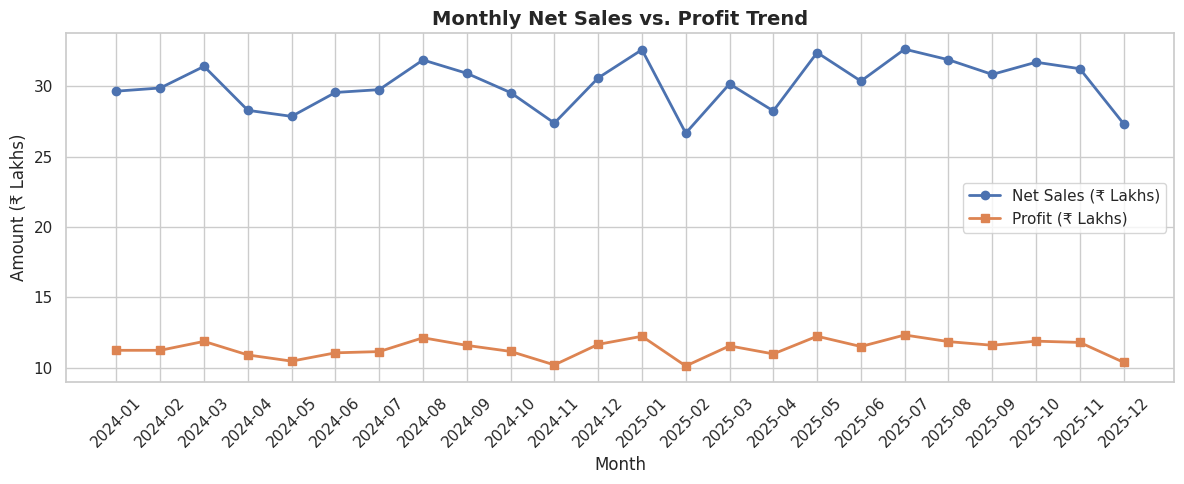

In [2]:
# Convert Order_Date to datetime and extract Year-Month
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Year_Month'] = df['Order_Date'].dt.to_period('M').astype(str)

monthly = df.groupby('Year_Month')[['Net_Sales_INR', 'Profit_INR']].sum().reset_index()

plt.figure(figsize=(12, 5))
plt.plot(monthly['Year_Month'], monthly['Net_Sales_INR'] / 1e5, marker='o', label='Net Sales (₹ Lakhs)', linewidth=2)
plt.plot(monthly['Year_Month'], monthly['Profit_INR'] / 1e5, marker='s', label='Profit (₹ Lakhs)', linewidth=2)
plt.title('Monthly Net Sales vs. Profit Trend', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Amount (₹ Lakhs)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_770/1545896570.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Category', y='Margin_Pct', palette='Set2')


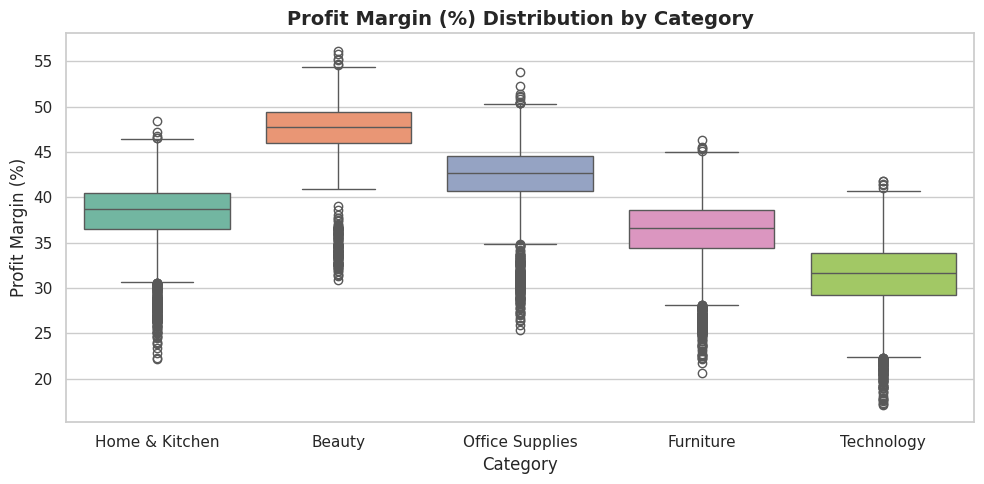

In [3]:
df['Margin_Pct'] = (df['Profit_INR'] / df['Net_Sales_INR']) * 100

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Category', y='Margin_Pct', palette='Set2')
plt.title('Profit Margin (%) Distribution by Category', fontsize=14, fontweight='bold')
plt.ylabel('Profit Margin (%)')
plt.xlabel('Category')
plt.tight_layout()
plt.show()

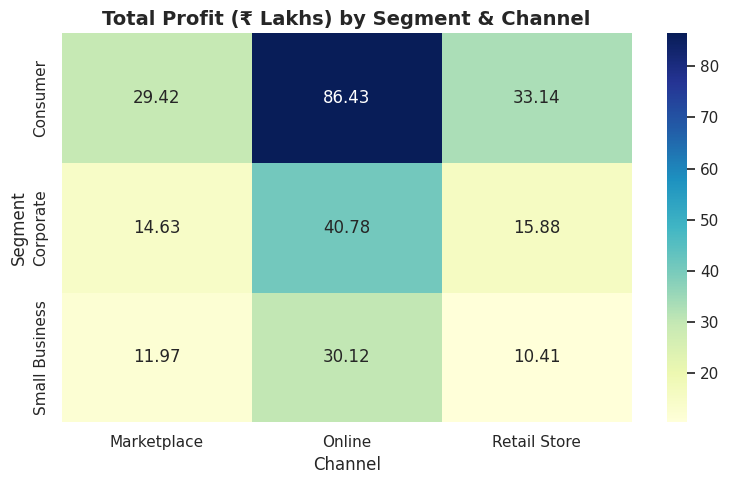

In [4]:
pivot_heatmap = df.pivot_table(
    values='Profit_INR',
    index='Segment',
    columns='Channel',
    aggfunc='sum'
) / 1e5  # Convert to Lakhs

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_heatmap, annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('Total Profit (₹ Lakhs) by Segment & Channel', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

/tmp/ipykernel_770/1631982525.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Discount', y='Margin_Pct', palette='coolwarm')


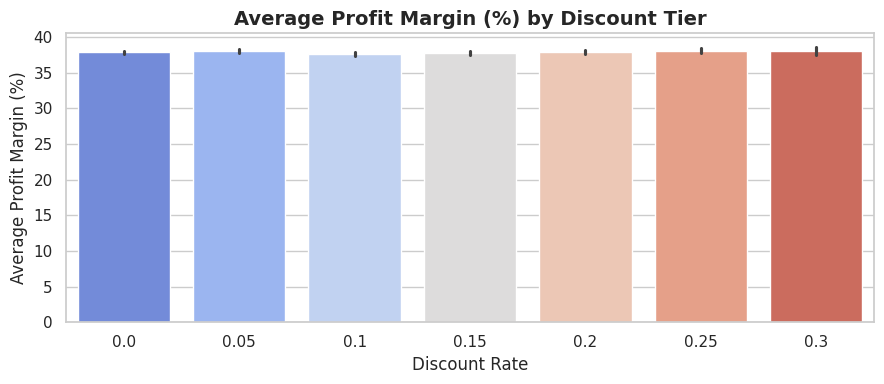

In [5]:
plt.figure(figsize=(9, 4))
sns.barplot(data=df, x='Discount', y='Margin_Pct', palette='coolwarm')
plt.title('Average Profit Margin (%) by Discount Tier', fontsize=14, fontweight='bold')
plt.ylabel('Average Profit Margin (%)')
plt.xlabel('Discount Rate')
plt.tight_layout()
plt.show()